# Notebook 03 — Multi-Object Tracking

**Objective.** Give each vehicle a consistent identity across frames and build per-vehicle trajectories. We compare three tracking algorithms on the same detections and choose a baseline.

**Background.** Notebook 02 produced boxes for each frame independently. Detection does not know that the motorcycle at (800, 600) in frame 100 is the same motorcycle at (803, 597) in frame 101. A violation rule needs exactly that link: a red-light or wrong-way decision is about **one vehicle's movement over time**. Tracking turns per-frame boxes into **tracks**, sequences of boxes sharing a `track_id`.

**Input.**
- `outputs/02_object_detection/detections/video-test.jsonl` — Detection Data from Notebook 02 (yolo26m @ 1280, stored confidence ≥ 0.10).
- `data/video-test.mp4` — frames, needed only by BoT-SORT (camera-motion compensation and appearance features).

**Output.**
- Per-frame **Tracking Data** for each tracker variant: `outputs/03_multi_object_tracking/tracks/video-test.<variant>.jsonl`.
- **Trajectories** of the chosen baseline: `video-test.<variant>.trajectories.json`.
- Comparison metrics, figures, and an annotated video.

**Structure.**
1. ByteTrack — the mechanism in detail.
2. OC-SORT — what changes under occlusion.
3. BoT-SORT — camera-motion compensation and appearance (ReID).
4. Comparison and baseline choice.

**Runs on the GPU server** (BoT-SORT's appearance model uses CUDA). Trackers come from **BoxMOT**, an AGPL-3.0 library.

## 0. Setup and shared tools

In [1]:
import json
import logging
import time
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import boxmot
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.optimize import linear_sum_assignment

from traffic_violation_detection.video import iter_frames, read_frame_at, read_video_metadata

%config InlineBackend.figure_formats = ["jpeg"]

# The GPU server has 255 CPU cores. With PyTorch's default of one thread per core, the CPU-side
# work of the appearance model oversubscribes the machine and slows to a crawl (observed while
# preparing this notebook). 16 threads is plenty.
torch.set_num_threads(16)
# BoxMOT installs its own INFO-level log handler when boxmot.utils is first imported, then logs every
# tracker's settings. Import it now and raise the level, so the notebook output stays readable.
import boxmot.utils  # noqa: E402
logging.getLogger("boxmot").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="IProgress not found")

print("BoxMOT", boxmot.__version__, "| PyTorch", torch.__version__, "| GPU", torch.cuda.get_device_name(0))

BoxMOT 26.0.0 | PyTorch 2.15.0+cu132 | GPU NVIDIA GeForce RTX 4090


In [2]:
def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"No pyproject.toml found in {start} or any parent directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SAMPLE_VIDEO = PROJECT_ROOT / "data" / "video-test.mp4"
DETECTIONS_PATH = PROJECT_ROOT / "outputs" / "02_object_detection" / "detections" / "video-test.jsonl"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "03_multi_object_tracking"
(OUTPUT_DIR / "tracks").mkdir(parents=True, exist_ok=True)

assert DETECTIONS_PATH.is_file(), "Run Notebook 02 first: its detections are this notebook's input"
detection_records = [json.loads(line) for line in DETECTIONS_PATH.read_text().splitlines()]
detector_config = json.loads(DETECTIONS_PATH.with_suffix(".config.json").read_text())
meta = read_video_metadata(SAMPLE_VIDEO)
FPS, W, H = meta["fps"], meta["width"], meta["height"]

assert [r["frame_index"] for r in detection_records] == list(range(meta["reported_frame_count"]))
print(f"{len(detection_records)} frames of detections from {detector_config['detector']['weights']} "
      f"@ imgsz {detector_config['detector']['imgsz']}, conf >= {detector_config['detector']['conf']}")

900 frames of detections from yolo26m.pt @ imgsz 1280, conf >= 0.1


### What we track

We track **vehicles only**: `bicycle`, `car`, `motorcycle`, `bus`, `truck`. Two classes from the detection file are left out:

- **`person`**: Notebook 02 showed that most persons are riders, already represented by their motorcycle. Pedestrians are not needed for the vehicle violations considered in Phase 1.
- **`traffic light`**: signals are static scene elements, handled in Notebook 04.

Association is **class-agnostic**: a box may match a track even if its class differs. The detector sometimes flips between `car` and `truck` for the same van, and that should not break the track. Each track's class is decided afterwards by majority vote.

In [3]:
VEHICLE_CLASSES = {1: "bicycle", 2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}


def vehicle_detections(record: dict) -> np.ndarray:
    # BoxMOT input: one row per detection, [x1, y1, x2, y2, confidence, class_id].
    rows = [[*d["bbox_xyxy"], d["confidence"], d["class_id"]] for d in record["detections"] if d["class_id"] in VEHICLE_CLASSES]
    return np.array(rows, dtype=np.float32).reshape(-1, 6)


per_frame = [len(vehicle_detections(r)) for r in detection_records]
high = [int((vehicle_detections(r)[:, 4] >= 0.5).sum()) for r in detection_records]
print(f"vehicle detections per frame: mean {np.mean(per_frame):.1f} (all stored, >= 0.10), {np.mean(high):.1f} with conf >= 0.5")

vehicle detections per frame: mean 74.3 (all stored, >= 0.10), 27.3 with conf >= 0.5


### Tracking Data contract and how a tracker is run

Every tracker variant is run by the same function. BoxMOT returns one row per **currently tracked** object: `[x1, y1, x2, y2, track_id, confidence, class_id, detection_index]`. Here `detection_index` points back to the input detection that the track matched in this frame. Each frame becomes one JSON line:

| key | meaning |
| --- | --- |
| `video_id`, `frame_index`, `timestamp_s` | from the Frame Data / Detection Data records |
| `tracking_session` | `"<video_id>/<variant>"` — **track ids are only unique within one session** |
| `tracks[]` | `track_id`, `class_id`, `class_name`, `confidence`, `bbox_xyxy`, `state`, `detection_index` |

`class_id` is the class of the **detection matched in this frame**, looked up through `detection_index`. This makes all trackers report the same thing: BoT-SORT's own output column holds a sticky per-track class, while ByteTrack and OC-SORT report the current detection's class. A first run of this notebook caught that difference in the validation step.

`state` is always `"tracked"` here: BoxMOT reports only tracks matched in the current frame. Tracks that are temporarily lost keep their id internally but are not output while lost. For trajectories, a vehicle's position is the **bottom-center** of its box, the point closest to where the vehicle touches the road. That is the natural point to test against stop lines and lanes later.

In [4]:
def run_tracker(variant: str, tracker, detection_records, need_frames: bool) -> dict:
    # Feed every frame's vehicle detections to the tracker; write Tracking Data JSONL; return run statistics.
    path = OUTPUT_DIR / "tracks" / f"{meta['video_id']}.{variant}.jsonl"
    frames = iter_frames(SAMPLE_VIDEO) if need_frames else iter([None] * len(detection_records))
    update_ms = []
    with path.open("w") as out:
        for record, frame in zip(detection_records, frames):
            dets = vehicle_detections(record)
            start = time.perf_counter()
            output = tracker.update(dets, None if frame is None else frame["image"])
            update_ms.append((time.perf_counter() - start) * 1000)
            tracks = []
            for row in (output if len(output) else []):
                det_index = int(row[7])
                class_id = int(dets[det_index, 5])  # class of the matched detection in this frame
                tracks.append({
                    "track_id": int(row[4]),
                    "class_id": class_id,
                    "class_name": VEHICLE_CLASSES[class_id],
                    "confidence": round(float(row[5]), 4),
                    "bbox_xyxy": [round(float(v), 2) for v in row[:4]],
                    "state": "tracked",
                    "detection_index": det_index,
                })
            line = {k: record[k] for k in ("video_id", "frame_index", "timestamp_s")}
            line["tracking_session"] = f"{record['video_id']}/{variant}"
            line["tracks"] = tracks
            out.write(json.dumps(line) + "\n")
    return {"variant": variant, "path": path, "update_ms": update_ms}


def load_tracks(path: Path) -> list[dict]:
    return [json.loads(line) for line in path.read_text().splitlines()]


def bottom_center(bbox):
    x1, y1, x2, y2 = bbox
    return ((x1 + x2) / 2, y2)


def build_trajectories(track_records: list[dict]) -> dict[int, dict]:
    # Group per-frame tracks into per-vehicle trajectories (frame indices, timestamps, bottom-center points).
    trajectories = defaultdict(lambda: {"frames": [], "timestamps_s": [], "points": [], "bboxes": [], "classes": []})
    for record in track_records:
        for t in record["tracks"]:
            trajectory = trajectories[t["track_id"]]
            trajectory["frames"].append(record["frame_index"])
            trajectory["timestamps_s"].append(record["timestamp_s"])
            trajectory["points"].append([round(v, 2) for v in bottom_center(t["bbox_xyxy"])])
            trajectory["bboxes"].append(t["bbox_xyxy"])
            trajectory["classes"].append(t["class_name"])
    for trajectory in trajectories.values():
        trajectory["class_name"] = Counter(trajectory["classes"]).most_common(1)[0][0]
        trajectory["class_changes"] = len(set(trajectory["classes"])) > 1
    return dict(trajectories)

### Proxy metrics (no ground truth yet)

Without labeled tracks, metrics such as IDF1 or HOTA cannot be computed; that is Notebook 09's job. Instead we measure symptoms of good and bad tracking:

| metric | why it matters | better |
| --- | --- | --- |
| **coverage** | share of the confident vehicle detections in the detection file (conf ≥ 0.5) that some track box overlaps (IoU ≥ 0.5) in the same frame. The reference is the same for every variant, even one that was fed fewer boxes | higher |
| **unique ids** | each new id is a new "vehicle"; a fragmented track creates extra ids | lower, at equal coverage |
| **median track length** | short tracks cannot support a rule that needs a crossing over time | higher |
| **short tracks** | tracks shorter than 0.5 s (30 frames) | lower |
| **suspected re-ids** | a track ends (not at the left, right or bottom border, where vehicles leave the frame), and within 0.5 s a *new* id starts near where it ended (within 1.5× its box width). Usually the same vehicle with a new id, i.e. **fragmentation** | lower |
| **class flips** | tracks whose detected class changes over their life (e.g. car ↔ truck) | informational |
| **update time** | tracker cost per frame, excluding detection and decoding | lower |

These are heuristics. A real vehicle can legitimately appear near where another disappeared, so the numbers are compared *between trackers* on the same input, not read as absolute error rates.

In [5]:
SHORT_TRACK = 30   # frames = 0.5 s at 59.94 FPS
REID_WINDOW = 30   # frames
EDGE = 5           # px: a track whose last box touches the left/right/bottom border has left the frame


def iou_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    # Pairwise IoU between [x1, y1, x2, y2] boxes (same function as Notebook 02).
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter)


def suspected_reids(trajectories: dict, last_frame: int) -> list[tuple[int, int]]:
    # Pairs (ended_id, new_id): a track ends and a new one starts nearby within REID_WINDOW frames.
    starts = sorted((t["frames"][0], tid) for tid, t in trajectories.items())
    pairs = []
    for tid, t in trajectories.items():
        end_frame = t["frames"][-1]
        if end_frame >= last_frame - 1:
            continue
        ex, ey = t["points"][-1]
        x1, _, x2, y2 = t["bboxes"][-1]
        if x1 <= EDGE or x2 >= W - EDGE or y2 >= H - EDGE:
            continue  # the vehicle left the frame; a new vehicle entering nearby is not a re-id
        radius = 1.5 * max(x2 - x1, 10)
        for start_frame, other in starts:
            if other == tid or not (end_frame < start_frame <= end_frame + REID_WINDOW):
                continue
            sx, sy = trajectories[other]["points"][0]
            if np.hypot(sx - ex, sy - ey) <= radius:
                pairs.append((tid, other))
                break
    return pairs


def coverage(track_records: list[dict], min_conf: float = 0.5, min_iou: float = 0.5) -> float:
    # Share of reference detections (all stored vehicle detections with conf >= min_conf) that some track box overlaps.
    covered = total = 0
    for record, det_record in zip(track_records, detection_records):
        dets = vehicle_detections(det_record)
        reference = dets[dets[:, 4] >= min_conf, :4]
        total += len(reference)
        if len(reference) and record["tracks"]:
            boxes = np.array([t["bbox_xyxy"] for t in record["tracks"]])
            covered += int((iou_matrix(reference, boxes).max(axis=1) >= min_iou).sum())
    return covered / total


def proxy_metrics(variant: str, track_records: list[dict], update_ms: list[float]) -> dict:
    trajectories = build_trajectories(track_records)
    lengths = np.array([len(t["frames"]) for t in trajectories.values()])
    return {
        "variant": variant,
        "coverage": coverage(track_records),
        "unique_ids": len(trajectories),
        "active_per_frame": float(np.mean([len(r["tracks"]) for r in track_records])),
        "median_length": float(np.median(lengths)),
        "short_tracks": int((lengths < SHORT_TRACK).sum()),
        "suspected_reids": len(suspected_reids(trajectories, len(track_records) - 1)),
        "class_flips": sum(t["class_changes"] for t in trajectories.values()),
        "update_ms": float(np.median(update_ms)),
    }


def print_metrics(rows: list[dict]):
    keys = ["variant", "coverage", "unique_ids", "active_per_frame", "median_length", "short_tracks", "suspected_reids", "class_flips", "update_ms"]
    print(" | ".join(f"{k:>16}" for k in keys))
    for row in rows:
        print(" | ".join(f"{row[k]:>16.3f}" if isinstance(row[k], float) else f"{row[k]:>16}" for k in keys))

In [6]:
def draw_tracks(image: np.ndarray, record: dict, trails: dict | None = None) -> np.ndarray:
    # Draw each track with a color derived from its id, its id label, and an optional trail of past bottom-centers.
    canvas = image.copy()
    for t in record["tracks"]:
        color = tuple(int(c) for c in np.random.default_rng(t["track_id"]).integers(60, 255, 3))
        x1, y1, x2, y2 = (int(round(v)) for v in t["bbox_xyxy"])
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
        label = f"{t['track_id']}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        cv2.rectangle(canvas, (x1, max(0, y1 - th - 6)), (x1 + tw + 4, y1), color, -1)
        cv2.putText(canvas, label, (x1 + 2, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2, cv2.LINE_AA)
        if trails is not None and t["track_id"] in trails:
            points = np.array(trails[t["track_id"]][-60:], dtype=np.int32)
            cv2.polylines(canvas, [points], False, color, 2, cv2.LINE_AA)
    return canvas


def trails_until(trajectories: dict, frame_index: int) -> dict:
    return {tid: [p for f, p in zip(t["frames"], t["points"]) if f <= frame_index] for tid, t in trajectories.items()}

## 1. ByteTrack

ByteTrack (Zhang et al., 2022) is a **tracking-by-detection** method: it does not look at pixels at all, only at boxes and scores. Each frame it runs four steps:

1. **Predict.** Every existing track has a **Kalman filter** that predicts where its box will be in the new frame, from the track's recent velocity.
2. **First association.** **High-confidence** detections (score ≥ `track_thresh`) are matched to predicted track boxes. The cost is `1 − IoU`, and the optimal one-to-one assignment is found with the **Hungarian algorithm**.
3. **Second association — the "byte" idea.** Tracks still unmatched are matched against the **low-confidence** detections (between `min_conf` and `track_thresh`), with a looser IoU requirement. A vehicle that is half occluded often gets a low score; instead of being discarded, that box keeps its track alive.
4. **Lifecycle.**
   - Unmatched high-confidence detections start **new** tracks, which become *confirmed* after `min_hits` matches.
   - Tracks unmatched for more than `max_lost_frames` frames are **removed**; until then they are *lost* but can be recovered.

We first look at steps 1–3 on real data, then run the full tracker.

### 1.1 Association between two frames: IoU cost and the Hungarian algorithm

We match the confident vehicle boxes of frame 0 to those of frame 1, and of frame 0 to frame 30 (0.5 s later), using the Hungarian algorithm on `1 − IoU`.

In [7]:
def hungarian_match(frame_a: int, frame_b: int, min_conf: float = 0.5, min_iou: float = 0.3):
    a = vehicle_detections(detection_records[frame_a]); a = a[a[:, 4] >= min_conf]
    b = vehicle_detections(detection_records[frame_b]); b = b[b[:, 4] >= min_conf]
    iou = iou_matrix(a[:, :4], b[:, :4])
    rows, cols = linear_sum_assignment(1 - iou)  # minimal total cost = maximal total IoU
    accepted = iou[rows, cols] >= min_iou
    return len(a), len(b), iou[rows, cols][accepted]


for frame_b in (1, 30):
    n_a, n_b, ious = hungarian_match(0, frame_b)
    print(f"frame 0 -> {frame_b:>2}: {n_a} vs {n_b} confident boxes, {len(ious)} matched with IoU >= 0.3, "
          f"median IoU of matches {np.median(ious):.2f}")

frame 0 ->  1: 31 vs 33 confident boxes, 30 matched with IoU >= 0.3, median IoU of matches 0.96
frame 0 -> 30: 31 vs 29 confident boxes, 16 matched with IoU >= 0.3, median IoU of matches 0.73


At 59.94 FPS, a vehicle barely moves between consecutive frames, so its boxes overlap almost completely: IoU alone is enough to match them. After 0.5 s, the overlap shrinks and fewer boxes can be matched by IoU alone. Bridging that kind of gap, which is what happens during an **occlusion**, is the job of the motion model.

### 1.2 Run ByteTrack on the whole video

BoxMOT defaults, tuned on the MOT17 benchmark: `track_thresh=0.6`, `min_conf=0.1`, `match_thresh=0.9`, `max_lost_frames=30`, `min_hits=3`.

Note that 30 lost frames means **0.5 s at our 59.94 FPS**, but 1 s at MOT17's 30 FPS. Frame-based settings do not transfer between frame rates.

In [8]:
print("ByteTrackConfig:", boxmot.ByteTrackConfig())
runs = {}
runs["bytetrack"] = run_tracker("bytetrack", boxmot.ByteTrack(), detection_records, need_frames=False)
bytetrack_records = load_tracks(runs["bytetrack"]["path"])
bytetrack_traj = build_trajectories(bytetrack_records)
print(f"{len(bytetrack_traj)} track ids; median update {np.median(runs['bytetrack']['update_ms']):.2f} ms/frame")

ByteTrackConfig: ByteTrackConfig(max_age=30, max_obs=50, min_hits=3, iou_threshold=0.3, asso_func='iou', centroid_max_distance=0.05, min_conf=0.1, track_thresh=0.6, match_thresh=0.9, second_match_thresh=0.5, unconfirmed_match_thresh=0.7, max_lost_frames=30, fuse_first_associate=True, fuse_unconfirmed_associate=True, motion_fusion='off', motion_fusion_lambda=0.98, motion_fusion_only_position=False, duplicate_distance_thresh=0.15, use_cmc=False, cmc_method='sof', cmc_min_conf=None)


155 track ids; median update 2.73 ms/frame


### 1.3 The Kalman filter: predicting through a gap

A Kalman filter keeps a **state** (here: position and velocity of the box's bottom-center) and its **uncertainty**. Every frame it does two things:

- **Predict.** Move the state forward with constant velocity; the uncertainty grows.
- **Update.** Blend in the new measurement. The less uncertain source gets more weight, and the uncertainty shrinks.

When no measurement arrives (occlusion), it keeps predicting. This is the box that ByteTrack tries to match when the vehicle reappears.

Below is a minimal constant-velocity Kalman filter (4 states: x, y, vx, vy), not BoxMOT's implementation. It shows the idea on a real trajectory from the ByteTrack run above. We hide 30 frames (0.5 s) of a vehicle's track and compare the filter's predictions during the gap with two alternatives: the true positions, and the naive guess "it stays where it was last seen".

43 candidate tracks; demo: track 211 (motorcycle), first 120 frames; hidden frames 90-119 of the track
error at end of 0.5 s gap: Kalman 50.7 px | last-seen position 124.8 px


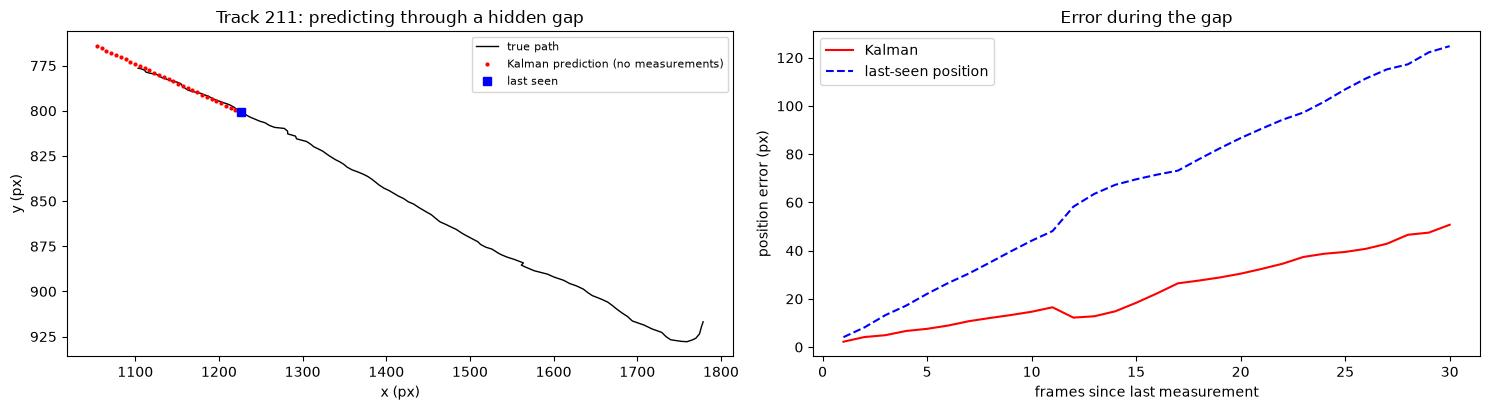

In [9]:
class ConstantVelocityKalman:
    # State [x, y, vx, vy]; measurements [x, y]; time step = 1 frame.
    def __init__(self, x, y, process_noise=1.0, measurement_noise=4.0):
        self.state = np.array([x, y, 0.0, 0.0])
        self.P = np.diag([10.0, 10.0, 100.0, 100.0])           # initial uncertainty: velocity unknown
        self.F = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], dtype=float)
        self.Hm = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], dtype=float)
        self.Q = np.eye(4) * process_noise
        self.R = np.eye(2) * measurement_noise

    def predict(self):
        self.state = self.F @ self.state
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.state[:2].copy()

    def update(self, x, y):
        innovation = np.array([x, y]) - self.Hm @ self.state
        S = self.Hm @ self.P @ self.Hm.T + self.R
        K = self.P @ self.Hm.T @ np.linalg.inv(S)                # Kalman gain: how much to trust the measurement
        self.state = self.state + K @ innovation
        self.P = (np.eye(4) - K @ self.Hm) @ self.P


GAP_START, GAP = 90, 30
WINDOW = GAP_START + GAP


def demo_window_ok(t) -> bool:
    # Tracked in every frame of the window, and the box never touches a border (bottom-center would be clipped).
    if len(t["frames"]) < WINDOW or t["frames"][WINDOW - 1] - t["frames"][0] != WINDOW - 1:
        return False
    return all(x1 > EDGE and x2 < W - EDGE and y2 < H - EDGE for x1, _, x2, y2 in t["bboxes"][:WINDOW])


candidates = [(tid, t) for tid, t in bytetrack_traj.items() if demo_window_ok(t)]
# The vehicle that moves the farthest during the window: a clear motion to predict.
demo_id, demo = max(candidates, key=lambda kv: np.hypot(*np.subtract(kv[1]["points"][WINDOW - 1], kv[1]["points"][0])))
points = np.array(demo["points"][:WINDOW])

kf = ConstantVelocityKalman(*points[0])
predicted = []
for i in range(1, GAP_START + GAP):
    p = kf.predict()
    if i < GAP_START:
        kf.update(*points[i])
    else:
        predicted.append(p)
predicted = np.array(predicted)
truth = points[GAP_START:GAP_START + GAP]
kalman_err = np.hypot(*(predicted - truth).T)
static_err = np.hypot(*(points[GAP_START - 1] - truth).T)
print(f"{len(candidates)} candidate tracks; demo: track {demo_id} ({demo['class_name']}), first {WINDOW} frames; "
      f"hidden frames {GAP_START}-{GAP_START + GAP - 1} of the track")
print(f"error at end of 0.5 s gap: Kalman {kalman_err[-1]:.1f} px | last-seen position {static_err[-1]:.1f} px")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].plot(points[:GAP_START + GAP, 0], points[:GAP_START + GAP, 1], "k-", linewidth=1, label="true path")
axes[0].plot(predicted[:, 0], predicted[:, 1], "r.", markersize=4, label="Kalman prediction (no measurements)")
axes[0].plot(*points[GAP_START - 1], "bs", label="last seen")
axes[0].invert_yaxis(); axes[0].set(xlabel="x (px)", ylabel="y (px)", title=f"Track {demo_id}: predicting through a hidden gap")
axes[0].legend(fontsize=8)
axes[1].plot(np.arange(1, GAP + 1), kalman_err, "r-", label="Kalman")
axes[1].plot(np.arange(1, GAP + 1), static_err, "b--", label="last-seen position")
axes[1].set(xlabel="frames since last measurement", ylabel="position error (px)", title="Error during the gap")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "kalman_gap_demo.png", dpi=100)
plt.show()

### 1.4 Does the second ("byte") association help here?

We run ByteTrack a second time, but only feed it detections with confidence ≥ 0.6. That removes everything the second association would use. If low-score boxes matter for this scene, this variant should lose coverage and fragment more.

In [10]:
high_only_records = [{**r, "detections": [d for d in r["detections"] if d["confidence"] >= 0.6]} for r in detection_records]
runs["bytetrack-highonly"] = run_tracker("bytetrack-highonly", boxmot.ByteTrack(), high_only_records, need_frames=False)

metrics = [
    proxy_metrics("bytetrack", bytetrack_records, runs["bytetrack"]["update_ms"]),
    proxy_metrics("bytetrack-highonly", load_tracks(runs["bytetrack-highonly"]["path"]), runs["bytetrack-highonly"]["update_ms"]),
]
print_metrics(metrics)

         variant |         coverage |       unique_ids | active_per_frame |    median_length |     short_tracks |  suspected_reids |      class_flips |        update_ms
       bytetrack |            0.909 |              155 |           31.384 |           87.000 |               20 |               15 |                7 |            2.734
bytetrack-highonly |            0.714 |              179 |           19.433 |           44.000 |               75 |               23 |                4 |            2.107


### 1.5 Visualizing ByteTrack's identities and trajectories

Boxes are colored by track id, with the id on each box and the last second of each trajectory drawn as a trail.

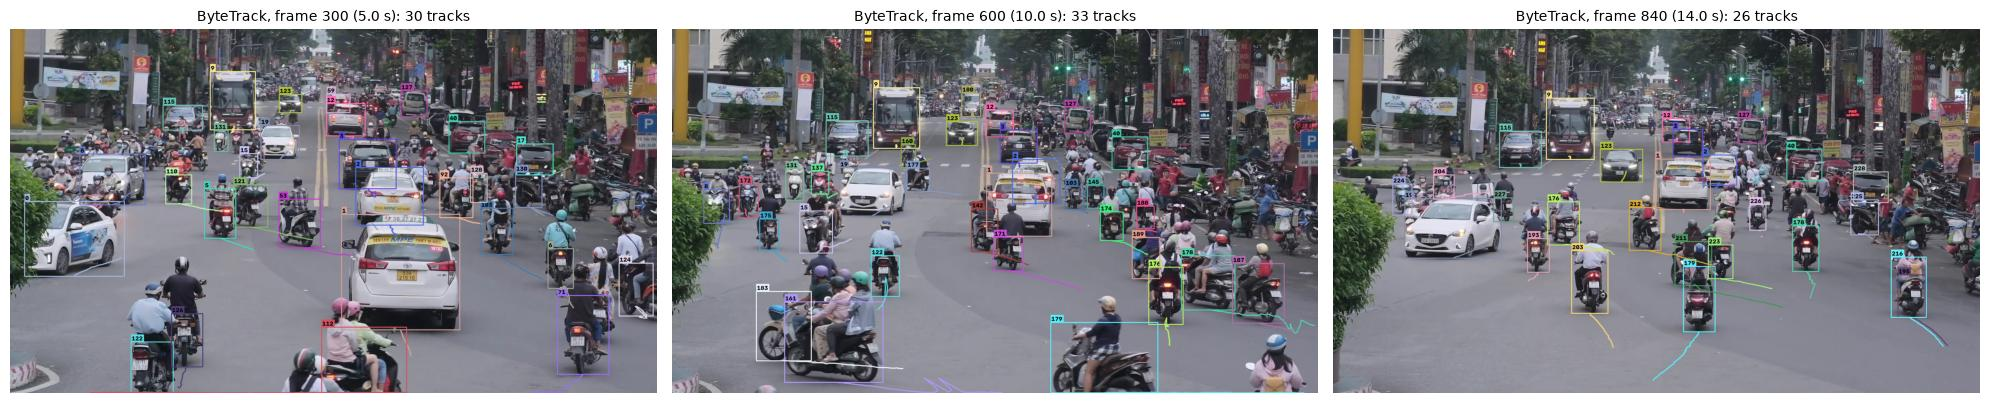

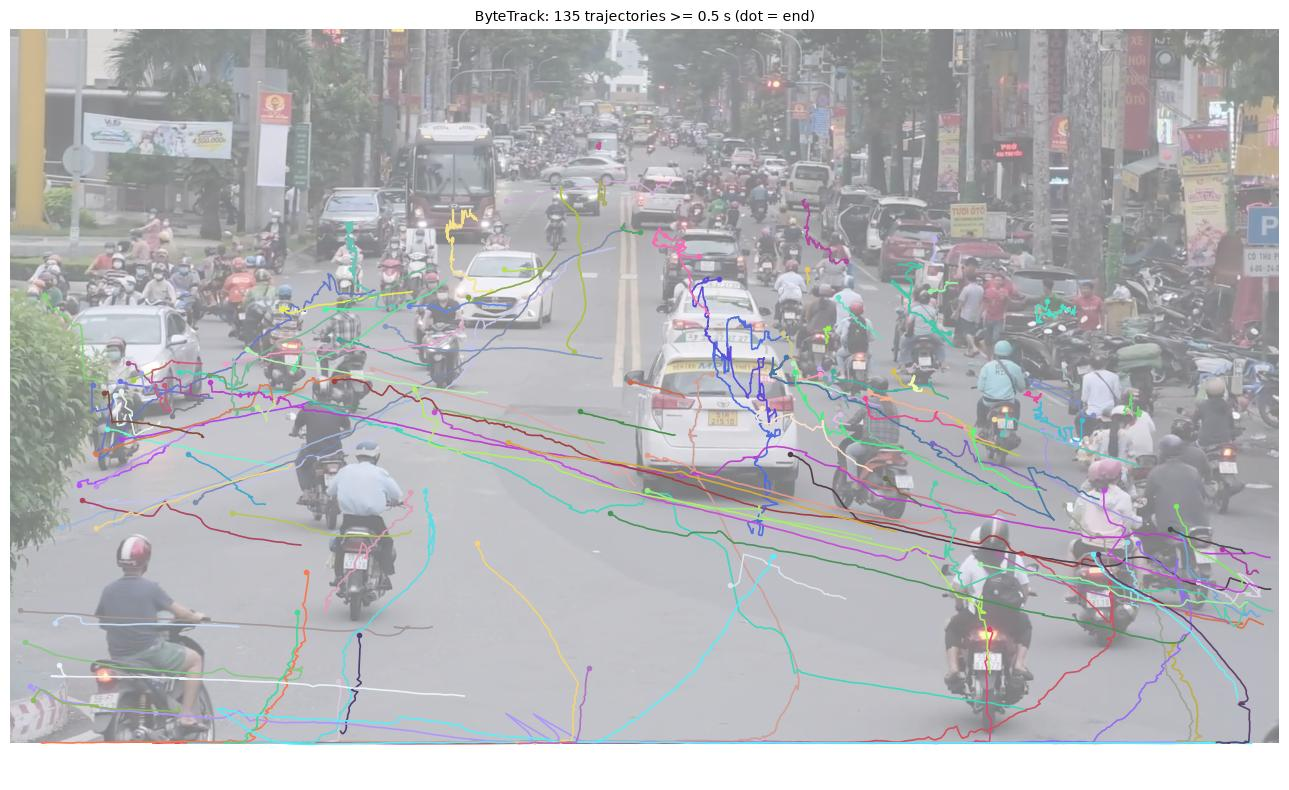

In [11]:
SHOW_FRAMES = [300, 600, 840]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.4))
for ax, k in zip(axes, SHOW_FRAMES):
    image = draw_tracks(read_frame_at(SAMPLE_VIDEO, k)["image"], bytetrack_records[k], trails_until(bytetrack_traj, k))
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"ByteTrack, frame {k} ({k / FPS:.1f} s): {len(bytetrack_records[k]['tracks'])} tracks", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "bytetrack_frames.jpg", dpi=90)
plt.show()


def plot_trajectories(ax, trajectories: dict, title: str, min_length: int = SHORT_TRACK):
    ax.imshow(cv2.cvtColor(read_frame_at(SAMPLE_VIDEO, 450)["image"], cv2.COLOR_BGR2RGB), alpha=0.55)
    shown = 0
    for tid, t in trajectories.items():
        if len(t["frames"]) < min_length:
            continue
        p = np.array(t["points"])
        color = np.random.default_rng(tid).integers(60, 255, 3)[::-1] / 255
        ax.plot(p[:, 0], p[:, 1], "-", color=color, linewidth=1.2)
        ax.plot(*p[-1], "o", color=color, markersize=3)
        shown += 1
    ax.set_title(f"{title}: {shown} trajectories >= {min_length / FPS:.1f} s (dot = end)", fontsize=10)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(14, 8))
plot_trajectories(ax, bytetrack_traj, "ByteTrack")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "bytetrack_trajectories.jpg", dpi=90)
plt.show()

### 1.6 A fragmentation case

We take one *suspected re-id* pair (a track ending and a new id starting close by shortly after) and look at the frames around the hand-over.

ByteTrack suspected re-ids: 15; showing the one with the longest ended track


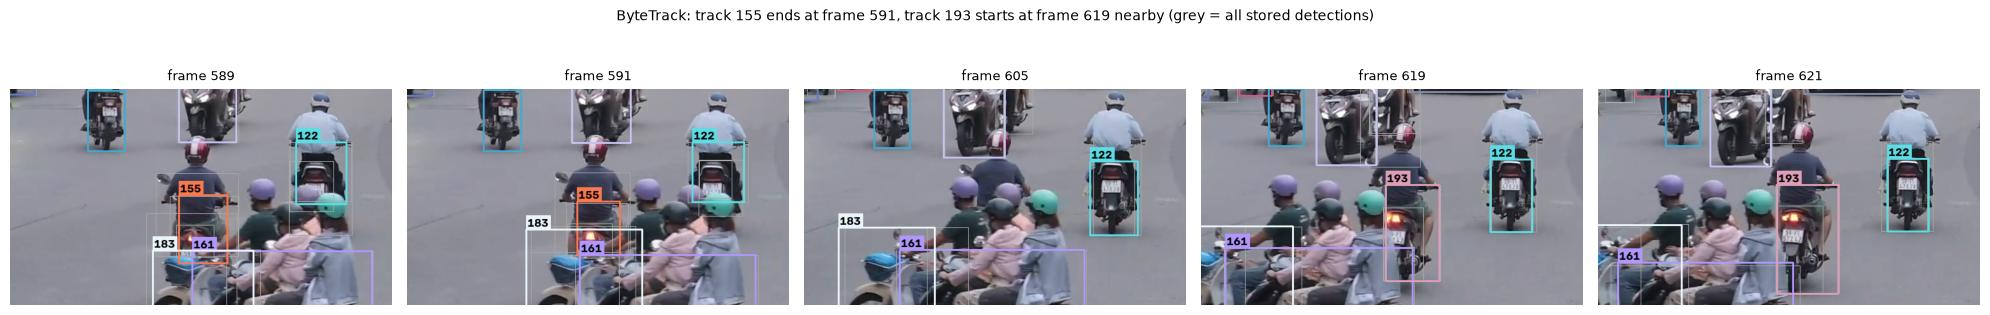

In [12]:
def show_reid_case(trajectories, records, variant, pair, save_name):
    ended, new = pair
    end_frame, start_frame = trajectories[ended]["frames"][-1], trajectories[new]["frames"][0]
    ex, ey = trajectories[ended]["points"][-1]
    rows = slice(int(max(0, ey - 260)), int(min(H, ey + 80)))
    cols = slice(int(max(0, ex - 300)), int(min(W, ex + 300)))
    frames_to_show = [end_frame - 2, end_frame, (end_frame + start_frame) // 2, start_frame, start_frame + 2]
    fig, axes = plt.subplots(1, len(frames_to_show), figsize=(20, 3.6))
    for ax, k in zip(axes, frames_to_show):
        k = min(max(k, 0), len(records) - 1)
        image = read_frame_at(SAMPLE_VIDEO, k)["image"]
        dets = [d for d in detection_records[k]["detections"] if d["class_id"] in VEHICLE_CLASSES]
        for d in dets:  # thin grey boxes: all stored detections, including low-confidence ones
            x1, y1, x2, y2 = (int(round(v)) for v in d["bbox_xyxy"])
            cv2.rectangle(image, (x1, y1), (x2, y2), (170, 170, 170), 1)
        image = draw_tracks(image, records[k])
        ax.imshow(cv2.cvtColor(image[rows, cols], cv2.COLOR_BGR2RGB))
        ax.set_title(f"frame {k}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{variant}: track {ended} ends at frame {end_frame}, track {new} starts at frame {start_frame} nearby "
                 f"(grey = all stored detections)", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / save_name, dpi=90)
    plt.show()


bytetrack_reids = suspected_reids(bytetrack_traj, len(bytetrack_records) - 1)
print(f"ByteTrack suspected re-ids: {len(bytetrack_reids)}; showing the one with the longest ended track")
if bytetrack_reids:
    case = max(bytetrack_reids, key=lambda pair: len(bytetrack_traj[pair[0]]["frames"]))
    show_reid_case(bytetrack_traj, bytetrack_records, "ByteTrack", case, "bytetrack_reid_case.jpg")

## 2. OC-SORT

OC-SORT (Cao et al., CVPR 2023) keeps the SORT recipe (Kalman filter plus IoU association) but addresses what goes wrong **during occlusion**. While a track is lost, its Kalman filter keeps extrapolating with no measurements, its velocity estimate drifts, and the predicted box moves away from where the vehicle will reappear. OC-SORT is *observation-centric*: it trusts the actual detections more than the filter.

- **Observation-centric re-update (ORU).** When a lost track is re-matched, OC-SORT rebuilds the filter's state along a virtual path between the last real observation and the new one. This undoes the drift accumulated during the gap.
- **Observation-centric momentum (OCM).** The association cost also includes **direction consistency**: the direction of motion computed from real observations a few frames apart (`delta_t`), weighted by `inertia`.
- **Observation-centric recovery (OCR).** Unmatched tracks get a second chance against their **last observed** box, not the predicted one.

**Difference from ByteTrack's defaults.** BoxMOT's OC-SORT uses `det_thresh=0.6` and `use_byte=False`, so it **ignores** the low-confidence boxes that ByteTrack's second stage uses. We run both the default and a variant with `use_byte=True` (OC-SORT + the byte association), to separate the two ideas.

In [13]:
print("OcSortConfig:", boxmot.OcSortConfig())
runs["ocsort"] = run_tracker("ocsort", boxmot.OcSort(), detection_records, need_frames=False)
runs["ocsort-byte"] = run_tracker("ocsort-byte", boxmot.OcSort(boxmot.OcSortConfig(use_byte=True)), detection_records, need_frames=False)

ocsort_records = load_tracks(runs["ocsort"]["path"])
ocsort_traj = build_trajectories(ocsort_records)
metrics += [
    proxy_metrics("ocsort", ocsort_records, runs["ocsort"]["update_ms"]),
    proxy_metrics("ocsort-byte", load_tracks(runs["ocsort-byte"]["path"]), runs["ocsort-byte"]["update_ms"]),
]
print_metrics(metrics)

OcSortConfig: OcSortConfig(max_age=30, max_obs=50, min_hits=3, iou_threshold=0.3, asso_func='iou', centroid_max_distance=0.05, min_conf=0.1, delta_t=3, inertia=0.1, use_byte=False, det_thresh=0.6, motion_fusion='off', motion_fusion_lambda=0.98, motion_fusion_only_position=False, fuse_detection_score=False, use_cmc=False, cmc_method='sof', cmc_min_conf=None)


         variant |         coverage |       unique_ids | active_per_frame |    median_length |     short_tracks |  suspected_reids |      class_flips |        update_ms
       bytetrack |            0.909 |              155 |           31.384 |           87.000 |               20 |               15 |                7 |            2.734
bytetrack-highonly |            0.714 |              179 |           19.433 |           44.000 |               75 |               23 |                4 |            2.107
          ocsort |            0.633 |              165 |           17.238 |           42.000 |               65 |               25 |                2 |            3.710
     ocsort-byte |            0.950 |              136 |           38.614 |          153.000 |                8 |                8 |               10 |            4.847


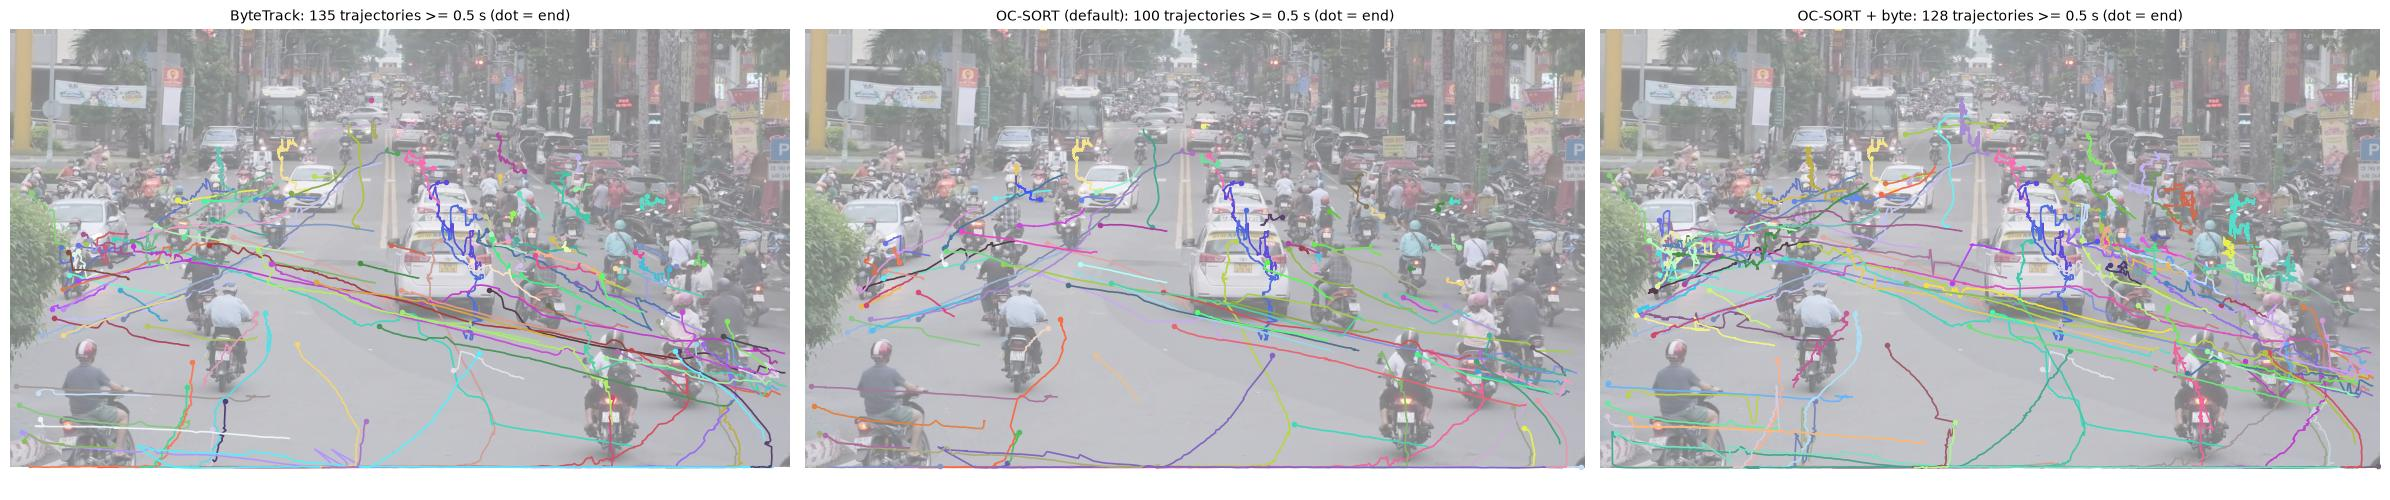

In [14]:
ocsort_byte_traj = build_trajectories(load_tracks(runs["ocsort-byte"]["path"]))
fig, axes = plt.subplots(1, 3, figsize=(24, 5))
plot_trajectories(axes[0], bytetrack_traj, "ByteTrack")
plot_trajectories(axes[1], ocsort_traj, "OC-SORT (default)")
plot_trajectories(axes[2], ocsort_byte_traj, "OC-SORT + byte")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "trajectories_bytetrack_vs_ocsort.jpg", dpi=80)
plt.show()

## 3. BoT-SORT

BoT-SORT (Aharon et al., 2022) builds on ByteTrack's two-stage association and adds two cues:

- **Camera-motion compensation (CMC).** If the camera pans or shakes, every object appears to move, and Kalman predictions land in the wrong place. CMC estimates the global image motion between frames (here with sparse optical flow, `cmc_method="sof"`) and shifts every track's prediction accordingly. Notebook 00 measured that our camera drifts by about 110 px over 15 s. That is about **0.1 px per frame** at 60 FPS, tiny compared with vehicle motion, so CMC is expected to change little *for association*.
- **Appearance (ReID).** A small re-identification network (`osnet_x0_25`, trained on person ReID) turns each box crop into an **embedding vector**. Association then combines IoU with embedding similarity, which helps re-link a vehicle after a long occlusion, when its predicted box is no longer reliable.

We run three variants to separate the cues: no CMC and no ReID; CMC only; and CMC + ReID (the BoxMOT default). The last one needs the video frames for the crops and is much slower.

In [15]:
print("BotSortConfig (defaults, tuned by BoxMOT):", boxmot.BotSortConfig())
runs["botsort-plain"] = run_tracker("botsort-plain", boxmot.BotSort(boxmot.BotSortConfig(use_cmc=False, use_embeddings=False)),
                                    detection_records, need_frames=True)
runs["botsort-cmc"] = run_tracker("botsort-cmc", boxmot.BotSort(boxmot.BotSortConfig(use_cmc=True, use_embeddings=False)),
                                  detection_records, need_frames=True)
reid = boxmot.ReIDConfig(model=str(PROJECT_ROOT / "weights" / "osnet_x0_25_msmt17.pt"), device="cuda:0")  # downloaded on first use
runs["botsort-cmc-reid"] = run_tracker("botsort-cmc-reid", boxmot.BotSort(reid=reid),
                                       detection_records, need_frames=True)

for variant in ["botsort-plain", "botsort-cmc", "botsort-cmc-reid"]:
    metrics.append(proxy_metrics(variant, load_tracks(runs[variant]["path"]), runs[variant]["update_ms"]))
print_metrics(metrics)

BotSortConfig (defaults, tuned by BoxMOT): BotSortConfig(max_age=30, max_obs=50, min_hits=3, iou_threshold=0.3, asso_func='iou', centroid_max_distance=0.05, track_high_thresh=0.6296854875023994, track_low_thresh=0.1014392537025336, new_track_thresh=0.6246494191492591, max_lost_frames=40, match_thresh=0.7722224024589055, proximity_thresh=0.6084297894561342, appearance_thresh=0.6188818853936099, use_cmc=True, cmc_method='sof', cmc_min_conf=None, fuse_first_associate=True, fuse_unconfirmed_associate=True, motion_fusion='off', motion_fusion_lambda=0.98, motion_fusion_only_position=False, fuse_iou=False, alpha_fixed_emb=0.9, duplicate_distance_thresh=0.15, use_embeddings=True, second_match_thresh=0.28795081514328974, unconfirmed_match_thresh=0.41148010638233784, unconfirmed_emb_scale=2.5445206391993294, removed_stracks_buffer=329, det_thresh=0.3)


         variant |         coverage |       unique_ids | active_per_frame |    median_length |     short_tracks |  suspected_reids |      class_flips |        update_ms
       bytetrack |            0.909 |              155 |           31.384 |           87.000 |               20 |               15 |                7 |            2.734
bytetrack-highonly |            0.714 |              179 |           19.433 |           44.000 |               75 |               23 |                4 |            2.107
          ocsort |            0.633 |              165 |           17.238 |           42.000 |               65 |               25 |                2 |            3.710
     ocsort-byte |            0.950 |              136 |           38.614 |          153.000 |                8 |                8 |               10 |            4.847
   botsort-plain |            0.861 |              153 |           27.781 |           81.000 |               22 |               29 |                7 |  

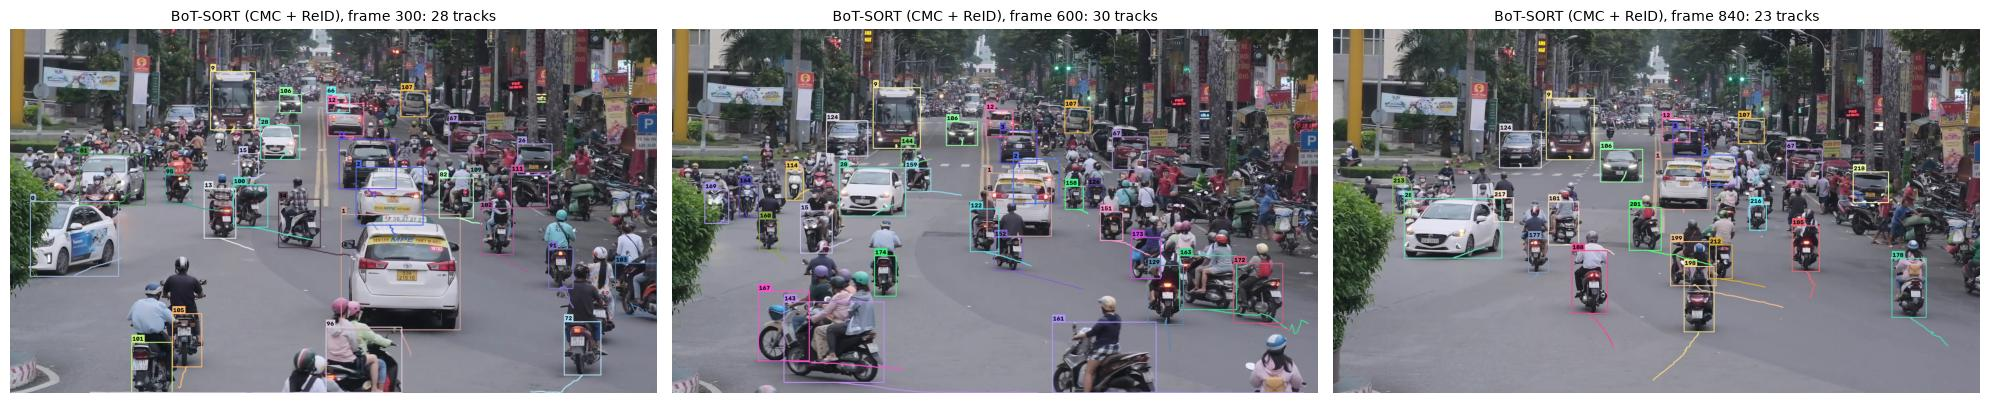

In [16]:
botsort_records = load_tracks(runs["botsort-cmc-reid"]["path"])
botsort_traj = build_trajectories(botsort_records)
fig, axes = plt.subplots(1, 3, figsize=(20, 4.4))
for ax, k in zip(axes, SHOW_FRAMES):
    image = draw_tracks(read_frame_at(SAMPLE_VIDEO, k)["image"], botsort_records[k], trails_until(botsort_traj, k))
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"BoT-SORT (CMC + ReID), frame {k}: {len(botsort_records[k]['tracks'])} tracks", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "botsort_frames.jpg", dpi=90)
plt.show()

## 4. Comparison and baseline choice

         variant |         coverage |       unique_ids | active_per_frame |    median_length |     short_tracks |  suspected_reids |      class_flips |        update_ms
       bytetrack |            0.909 |              155 |           31.384 |           87.000 |               20 |               15 |                7 |            2.734
bytetrack-highonly |            0.714 |              179 |           19.433 |           44.000 |               75 |               23 |                4 |            2.107
          ocsort |            0.633 |              165 |           17.238 |           42.000 |               65 |               25 |                2 |            3.710
     ocsort-byte |            0.950 |              136 |           38.614 |          153.000 |                8 |                8 |               10 |            4.847
   botsort-plain |            0.861 |              153 |           27.781 |           81.000 |               22 |               29 |                7 |  

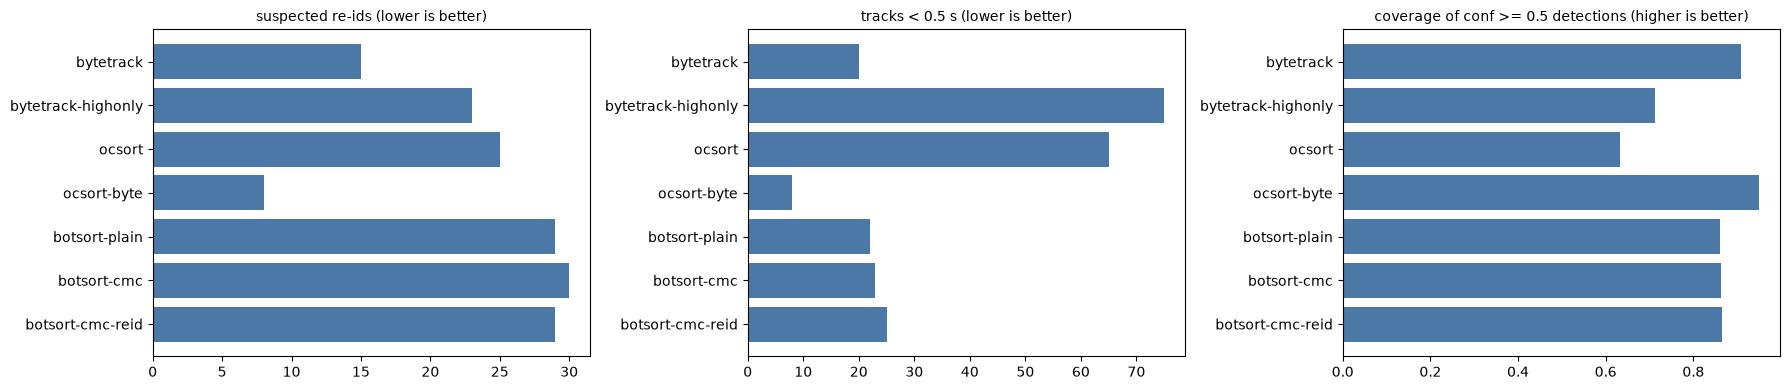

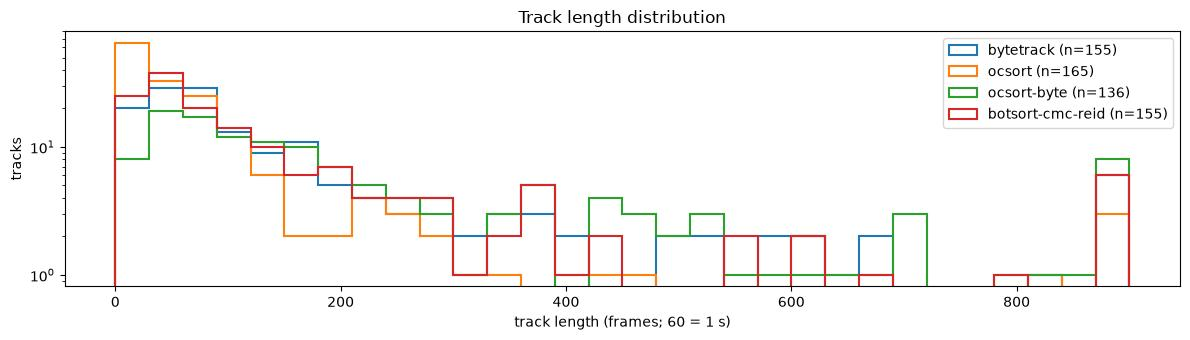

In [17]:
print_metrics(metrics)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
names = [m["variant"] for m in metrics]
for ax, key, title in zip(axes, ["suspected_reids", "short_tracks", "coverage"],
                          ["suspected re-ids (lower is better)", "tracks < 0.5 s (lower is better)", "coverage of conf >= 0.5 detections (higher is better)"]):
    ax.barh(names, [m[key] for m in metrics], color="#4C78A8")
    ax.set_title(title, fontsize=10)
    ax.invert_yaxis()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "tracker_comparison.png", dpi=100)
plt.show()

length_bins = np.arange(0, 901, 30)
fig, ax = plt.subplots(figsize=(12, 3.5))
for variant in ["bytetrack", "ocsort", "ocsort-byte", "botsort-cmc-reid"]:
    lengths = [len(t["frames"]) for t in build_trajectories(load_tracks(runs[variant]["path"])).values()]
    ax.hist(lengths, bins=length_bins, histtype="step", linewidth=1.5, label=f"{variant} (n={len(lengths)})")
ax.set(xlabel="track length (frames; 60 = 1 s)", ylabel="tracks", title="Track length distribution", yscale="log")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "track_lengths.png", dpi=100)
plt.show()

**Side by side on the same frames.** ByteTrack, OC-SORT + byte, and BoT-SORT (CMC + ReID) on one zoomed region over time. Identical vehicles should keep identical ids within each row.

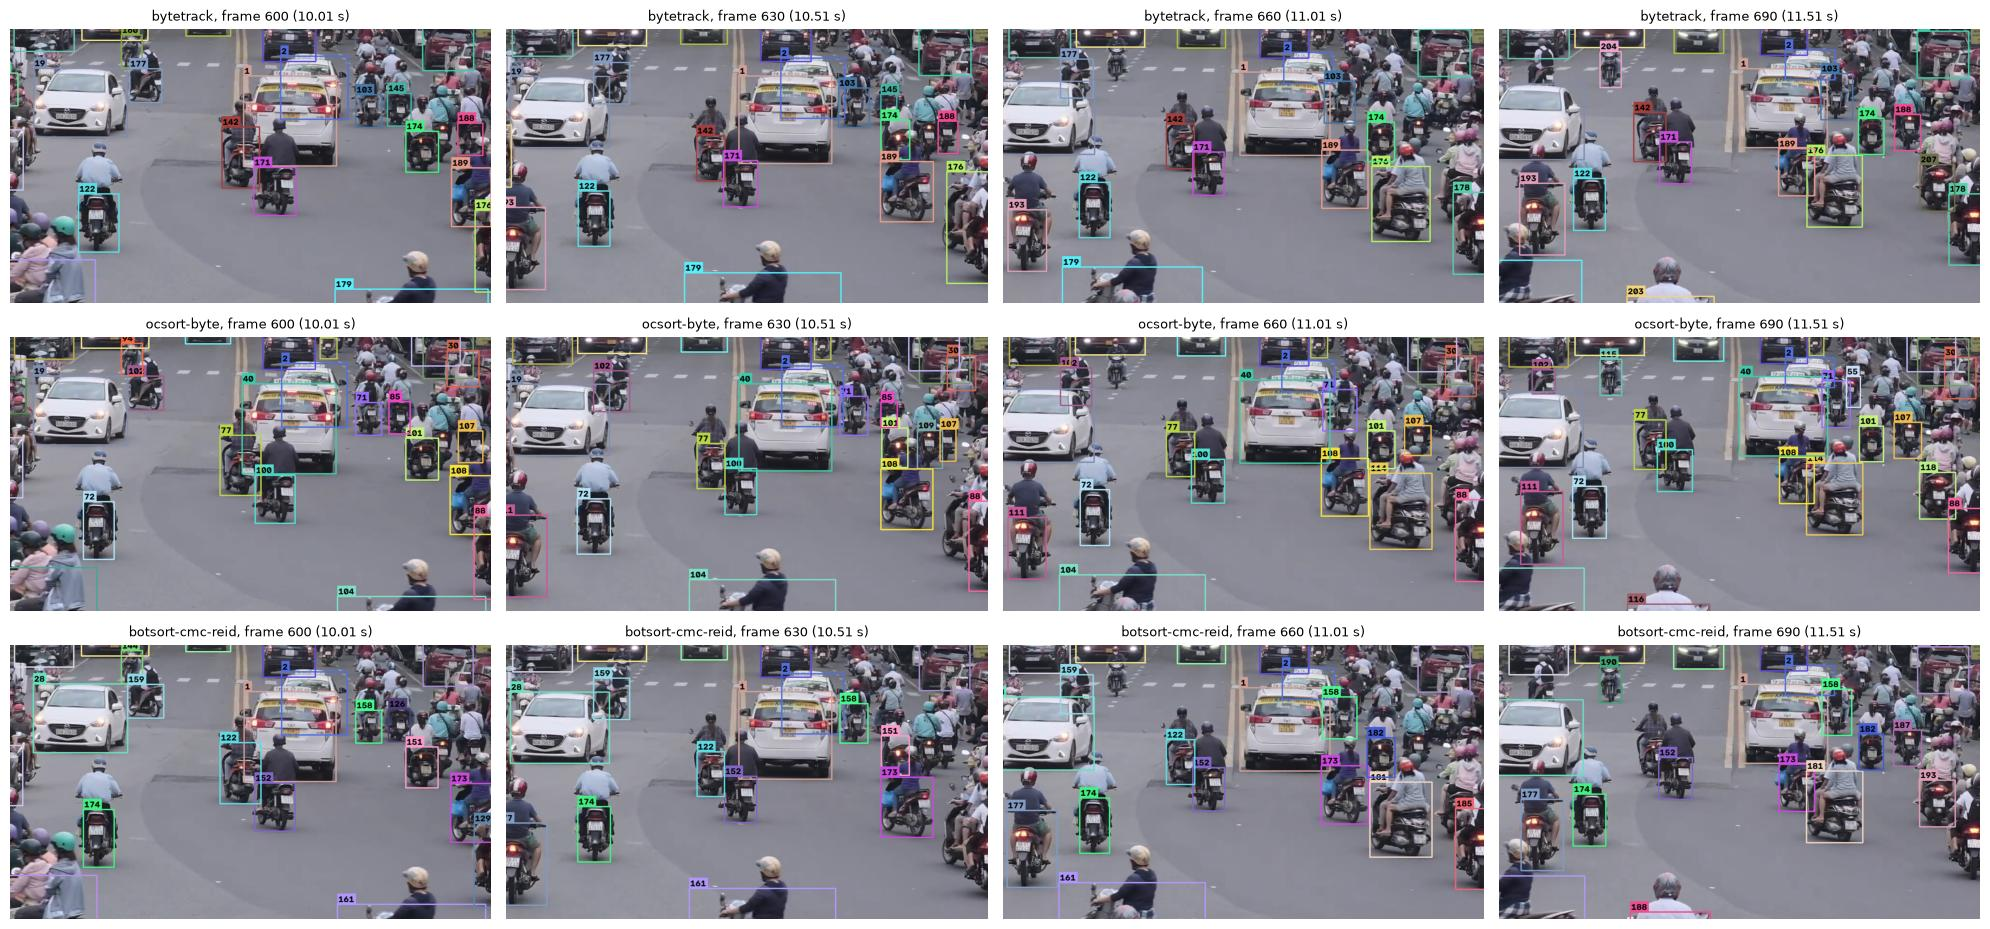

In [18]:
COMPARE_REGION = (slice(330, 900), slice(450, 1450))
COMPARE_FRAMES = [600, 630, 660, 690]
fig, axes = plt.subplots(3, len(COMPARE_FRAMES), figsize=(20, 9.5))
for row, variant in enumerate(["bytetrack", "ocsort-byte", "botsort-cmc-reid"]):
    records = load_tracks(runs[variant]["path"])
    for col, k in enumerate(COMPARE_FRAMES):
        image = draw_tracks(read_frame_at(SAMPLE_VIDEO, k)["image"], records[k])
        axes[row, col].imshow(cv2.cvtColor(image[COMPARE_REGION], cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"{variant}, frame {k} ({k / FPS:.2f} s)", fontsize=9)
        axes[row, col].axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "side_by_side.jpg", dpi=80)
plt.show()

### Choosing the baseline

**Decision rule, fixed before looking at the table:**

1. Prefer the variant with the **fewest suspected re-ids per tracked vehicle** (fragmentation hurts violation rules the most).
2. Require coverage within 5 percentage points of the best variant.
3. Use speed only as a tie-breaker.

**A metric bug caught in a first run.** The first execution of this notebook computed coverage against each variant's *own* input. The high-confidence-only variant was then judged on an easier denominator and won the selection, while tracking far fewer vehicles per frame. Coverage is now measured against the same reference detections for every variant (see the metrics table above). Suspected re-ids also no longer count vehicles leaving the frame at a border, after inspecting a case where a new vehicle entered right where another had left.

In [19]:
best_coverage = max(m["coverage"] for m in metrics)
eligible = [m for m in metrics if m["coverage"] >= best_coverage - 0.05]
for m in metrics:
    m["reids_per_100_ids"] = 100 * m["suspected_reids"] / m["unique_ids"]
baseline = min(eligible, key=lambda m: (m["reids_per_100_ids"], m["update_ms"]))
BASELINE = baseline["variant"]

print(f"{'variant':<20} {'coverage':>9} {'re-ids/100 ids':>15} {'eligible':>9}")
for m in metrics:
    print(f"{m['variant']:<20} {m['coverage']:>9.3f} {m['reids_per_100_ids']:>15.1f} {str(m in eligible):>9}")
print(f"\nBaseline tracker: {BASELINE}")

variant               coverage  re-ids/100 ids  eligible
bytetrack                0.909             9.7      True
bytetrack-highonly       0.714            12.8     False
ocsort                   0.633            15.2     False
ocsort-byte              0.950             5.9      True
botsort-plain            0.861            19.0     False
botsort-cmc              0.862            19.6     False
botsort-cmc-reid         0.865            18.7     False

Baseline tracker: ocsort-byte


### Save the baseline's trajectories and an annotated video

The trajectories file is the main input for the scene configuration (Notebook 04) and the violation rules (Notebook 05). For each track it stores:

- the frame indices and timestamps it was tracked in;
- its bottom-center points and boxes;
- its majority class.

Track ids are only meaningful within `tracking_session`.

In [20]:
baseline_records = load_tracks(runs[BASELINE]["path"])
baseline_traj = build_trajectories(baseline_records)
trajectories_path = OUTPUT_DIR / "tracks" / f"{meta['video_id']}.{BASELINE}.trajectories.json"
trajectories_path.write_text(json.dumps({
    "tracking_session": f"{meta['video_id']}/{BASELINE}",
    "video": {k: v for k, v in meta.items() if k != "path"},
    "detections_source": str(DETECTIONS_PATH.relative_to(PROJECT_ROOT)),
    "position": "bottom-center of bbox_xyxy, original-frame pixels",
    "tracks": {str(tid): {k: v for k, v in t.items() if k != "classes"} for tid, t in baseline_traj.items()},
}))

video_path = OUTPUT_DIR / f"{meta['video_id']}_{BASELINE}.mp4"
size = (W // 2, H // 2)
writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"mp4v"), FPS, size)
try:
    for frame, record in zip(iter_frames(SAMPLE_VIDEO), baseline_records):
        canvas = draw_tracks(frame["image"], record, trails_until(baseline_traj, frame["frame_index"]))
        writer.write(cv2.resize(canvas, size, interpolation=cv2.INTER_AREA))
finally:
    writer.release()

summary = {"metrics": metrics, "baseline": BASELINE, "boxmot": boxmot.__version__,
           "configs": {"bytetrack": str(boxmot.ByteTrackConfig()), "ocsort": str(boxmot.OcSortConfig()), "botsort": str(boxmot.BotSortConfig())}}
(OUTPUT_DIR / "tracking_summary.json").write_text(json.dumps(summary, indent=2))
print("wrote", trajectories_path.relative_to(PROJECT_ROOT), f"({trajectories_path.stat().st_size / 1e6:.1f} MB),",
      video_path.relative_to(PROJECT_ROOT), f"({video_path.stat().st_size / 1e6:.1f} MB)")

wrote outputs/03_multi_object_tracking/tracks/video-test.ocsort-byte.trajectories.json (2.6 MB), outputs/03_multi_object_tracking/video-test_ocsort-byte.mp4 (52.1 MB)


## 5. Validation

In [21]:
checks = {}
for variant, run in runs.items():
    records = load_tracks(run["path"])
    ids_per_frame_unique = all(len({t["track_id"] for t in r["tracks"]}) == len(r["tracks"]) for r in records)
    checks[f"{variant}: one record per frame"] = [r["frame_index"] for r in records] == list(range(len(detection_records)))
    checks[f"{variant}: a track id appears at most once per frame"] = ids_per_frame_unique
inputs_of = {"bytetrack-highonly": high_only_records}
for variant, run in runs.items():
    records = load_tracks(run["path"])
    source = inputs_of.get(variant, detection_records)
    ok = True
    for r, d in zip(records, source):
        dets = vehicle_detections(d)
        for t in r["tracks"]:
            if not (0 <= t["detection_index"] < len(dets)) or int(dets[t["detection_index"], 5]) != t["class_id"]:
                ok = False
    checks[f"{variant}: detection_index points to a vehicle detection of the same class"] = ok

reloaded = json.loads(trajectories_path.read_text())
checks["trajectories: frames strictly increasing in every track"] = all(
    np.all(np.diff(t["frames"]) > 0) for t in reloaded["tracks"].values())
checks["trajectories: timestamps == frame_index / fps"] = all(
    np.allclose(np.array(t["timestamps_s"]), np.array(t["frames"]) / FPS, atol=1e-6) for t in reloaded["tracks"].values())
checks["trajectories: points inside the frame"] = all(
    0 <= x <= W and 0 <= y <= H for t in reloaded["tracks"].values() for x, y in t["points"])
checks["annotated video has one frame per input frame"] = read_video_metadata(video_path)["reported_frame_count"] == len(detection_records)

for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
assert all(checks.values()), "One or more checks failed - see above"

[PASS] bytetrack: one record per frame
[PASS] bytetrack: a track id appears at most once per frame
[PASS] bytetrack-highonly: one record per frame
[PASS] bytetrack-highonly: a track id appears at most once per frame
[PASS] ocsort: one record per frame
[PASS] ocsort: a track id appears at most once per frame
[PASS] ocsort-byte: one record per frame
[PASS] ocsort-byte: a track id appears at most once per frame
[PASS] botsort-plain: one record per frame
[PASS] botsort-plain: a track id appears at most once per frame
[PASS] botsort-cmc: one record per frame
[PASS] botsort-cmc: a track id appears at most once per frame
[PASS] botsort-cmc-reid: one record per frame
[PASS] botsort-cmc-reid: a track id appears at most once per frame
[PASS] bytetrack: detection_index points to a vehicle detection of the same class
[PASS] bytetrack-highonly: detection_index points to a vehicle detection of the same class
[PASS] ocsort: detection_index points to a vehicle detection of the same class
[PASS] ocsort

## Results

All numbers come from the outputs above. Setup: 900 frames, vehicles only, proxy metrics, no ground truth.

**Low-confidence boxes are essential in this scene.**

- Two variants ignore boxes below 0.6: OC-SORT with default settings (coverage 0.63) and ByteTrack fed only high-confidence boxes (0.71).
- Both lose roughly a third of the confident vehicle detections. They also fragment far more: 65–75 tracks shorter than 0.5 s, against 8–20 for the variants that use low-confidence boxes.
- Dense, partly occluded motorcycles often score below 0.6, so the second ("byte") association is what keeps them tracked.

**OC-SORT + byte is the best variant on every proxy that matters.**

| proxy | OC-SORT + byte | ByteTrack |
| --- | --- | --- |
| coverage | 0.95 | 0.91 |
| median track length | 153 frames (2.6 s) | 87 frames |
| tracks shorter than 0.5 s | 8 | 20 |
| suspected re-ids | 8 | 15 |

- Combining observation-centric recovery with the low-confidence association works better here than either idea alone.
- It costs about 5 ms per frame, against about 3 ms for ByteTrack. Both are negligible next to detection.

**BoT-SORT did not help on this video.**

- Coverage is about 0.86, with about 29 suspected re-ids.
- **Camera-motion compensation changed nothing measurable**, as expected for a drift of about 0.1 px per frame.
- **ReID** gave no improvement and cost about 70 ms per frame, roughly 25× slower. Its appearance model was trained on people, not vehicles.
- BoxMOT's tuned BoT-SORT thresholds (e.g. `new_track_thresh` ≈ 0.62) may also not suit this scene.

**Mechanism demonstrations.**

- At 59.94 FPS, boxes in consecutive frames overlap with a median IoU of 0.96. After 0.5 s, only about half of the confident boxes can still be matched by IoU alone (median IoU 0.73), which is why a motion model is needed.
- In section 1.3, the Kalman filter's prediction through a hidden 0.5 s gap stayed much closer to the true position than the "last seen" guess.

**Baseline: `ocsort-byte`.** It was chosen by the decision rule stated before the comparison, after fixing the coverage metric (see section 4).

**Caveats on the winner.**

- **More active tracks than confident detections.** It keeps about 39 tracks active per frame, while there are only about 27 confident vehicle detections per frame, so it also follows low-confidence objects. Some of these are real distant or occluded vehicles. Others may be duplicates, such as the nested motorcycle boxes seen in Notebook 02, or false positives. More active tracks also mean more chances for false candidate events later.
- **Class flips.** It has the most tracks whose detected class flips (10). Use the stored majority-vote class, not the per-frame class.

## Limitations

- **Proxy metrics only.**
  - The suspected re-id heuristic misses identity swaps between two existing vehicles (no new id is created).
  - It can also flag a genuinely new vehicle that appears where another disappeared.
  - Real IDF1/HOTA scores need labeled tracks (Notebook 09).
- **Default settings, not tuned.** Frame-based settings were designed for 30 FPS benchmarks: `max_age` = 30 frames means only 0.5 s at 59.94 FPS.
- **One 15-second clip** from one camera.
- **Position jitter.** Bottom-center positions jump when the bottom of a box is occluded, for example a taxi behind motorcycles. This shows up as zig-zag trajectories, and Notebook 05 should smooth positions or use tolerances.
- **Not tracked.** Pedestrians are not tracked, and riders are represented only by their vehicle.
- **Installation.** BoxMOT is AGPL-3.0, and it is installed with `--no-deps` because it pins an older `opencv-python` (see `pyproject.toml`).

## Conclusion

**Completion criterion** — *the notebook can track vehicles over time and construct usable trajectories, with documented failure cases; a tracking ID is not assumed to remain globally unique or perfectly stable*: **met.**

- Every variant produced valid Tracking Data and passed all validation checks.
- The baseline's trajectories are saved with their `tracking_session`, so track ids are scoped to one video and one tracker run.
- The failure cases are documented: fragmentation, dependence on low-confidence boxes, position jitter, and the metric pitfall.

**Readiness for integration.**

- `outputs/03_multi_object_tracking/tracks/video-test.ocsort-byte.jsonl` and `.trajectories.json` are the inputs for Notebooks 04–05.
- `run_tracker` and `build_trajectories` are candidates for `src/traffic_violation_detection/tracking.py`, once Notebook 05 has shown which trajectory fields the rules actually need.

**Next: Notebook 04 — scene configuration.**

- Notebook 00 found a camera drift of up to about 110 px, so stop lines and lanes drawn in one frame's pixel coordinates will not line up with the whole video.
- Planned approach: register frames to a reference frame, and express both the scene geometry and the trajectories in that reference.